In [1]:
import pandas as pd
import requests
import json
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

def plot_samples(df, class_id, num_samples=3):
    fig, axes = plt.subplots(nrows=1, ncols=num_samples, figsize=(30, 10))
    urls = df[df["result"] == class_id]["image"].to_numpy()
    num_samples = min(num_samples, urls.shape[0])
    text = next((opt["label"] for opt in label_to_text if opt["value"] == str(class_id)))

    fig.suptitle(f"{text} (label={class_id})", fontsize=60)
    for i in range(num_samples):
        response = requests.get(urls[i])
        img = Image.open(BytesIO(response.content))
        axes[i].imshow(img)
        axes[i].axis("off")

with open("data/interface.json", "r") as f:
    label_to_text = json.load(f)["view"]["items"][0]["items"][1]["options"]

df = pd.read_csv("data/DATASETS_HA_YATASKS_labeled_subsample.csv")
df.head(5)

,item_id,image,image_id_ext,result,label
0,1366942000196,http://labelimages.avito.ru/15712419117.jpg,15712419117,5,кабинет
1,1365283500265,http://labelimages.avito.ru/15750299376.jpg,15750299376,11,гардеробная / кладовая / постирочная
2,1356640000903,http://labelimages.avito.ru/15537042731.jpg,15537042731,11,гардеробная / кладовая / постирочная
3,1365335500008,http://labelimages.avito.ru/15751542177.jpg,15751542177,6,детская
4,1357876758876,http://labelimages.avito.ru/15563093115.jpg,15563093115,11,гардеробная / кладовая / постирочная


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   item_id       82 non-null     int64
 1   image         82 non-null     str  
 2   image_id_ext  82 non-null     int64
 3   result        82 non-null     int64
 4   label         82 non-null     str  
dtypes: int64(3), str(2)
memory usage: 3.3 KB


In [10]:
df.groupby(["label"])["image"].count()

label
балкон / лоджия                          4
ванная комната                           3
вид из окна / с балкона                  4
гардеробная / кладовая / постирочная    11
гостиная                                 2
детская                                 12
дом снаружи / двор                       2
другое                                   4
кабинет                                 10
комната без мебели                       4
коридор / прихожая                       4
кухня / столовая                         2
кухня-гостиная                           3
не могу дать ответ / не ясно             2
подъезд / лестничная площадка            2
предметы интерьера / быт.техника         3
совмещенный санузел                      2
спальня                                  3
туалет                                   3
универсальная комната                    2
Name: image, dtype: int64

Done: 1/20	Done: 2/20	Done: 3/20	Done: 4/20	Done: 5/20	Done: 6/20	Done: 7/20	Done: 8/20	Done: 9/20	Done: 10/20	Done: 11/20	Done: 12/20	Done: 13/20	Done: 14/20	Done: 15/20	Done: 16/20	Done: 17/20	Done: 18/20	Done: 19/20	Done: 20/20	

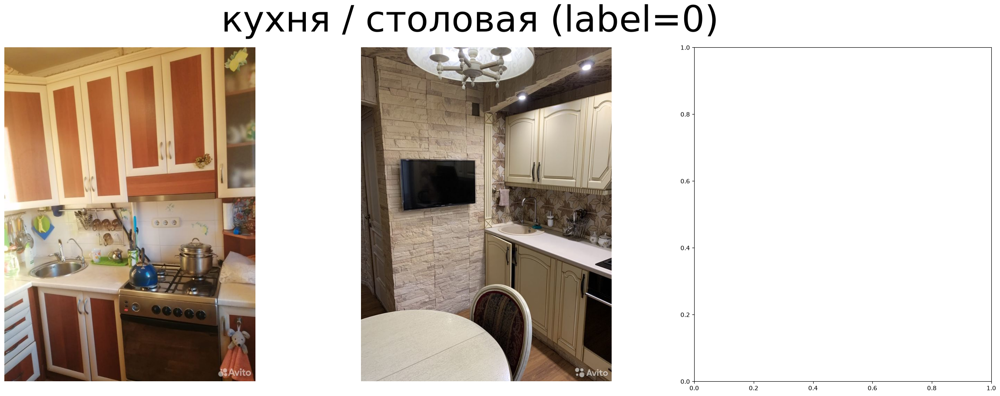

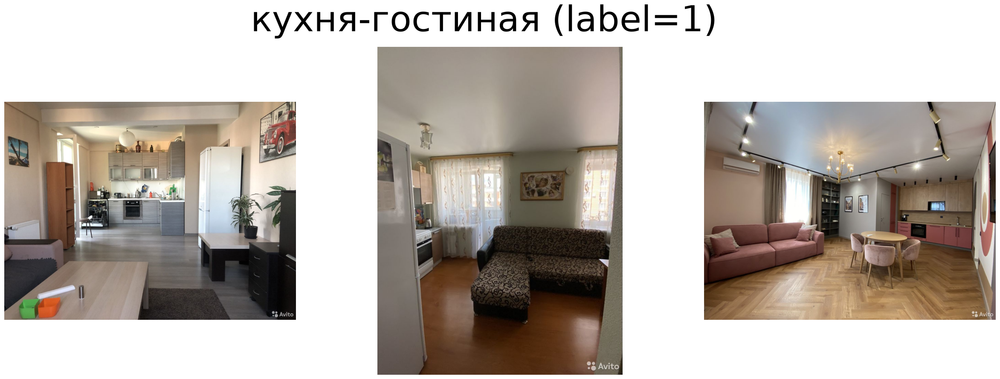

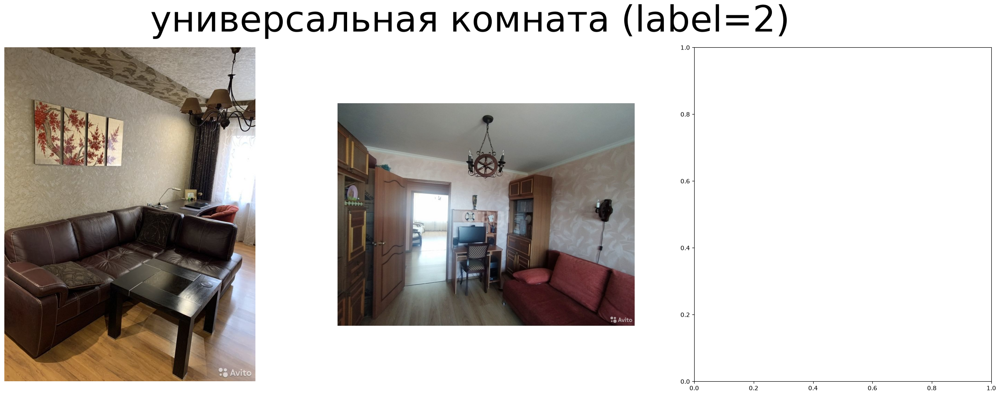

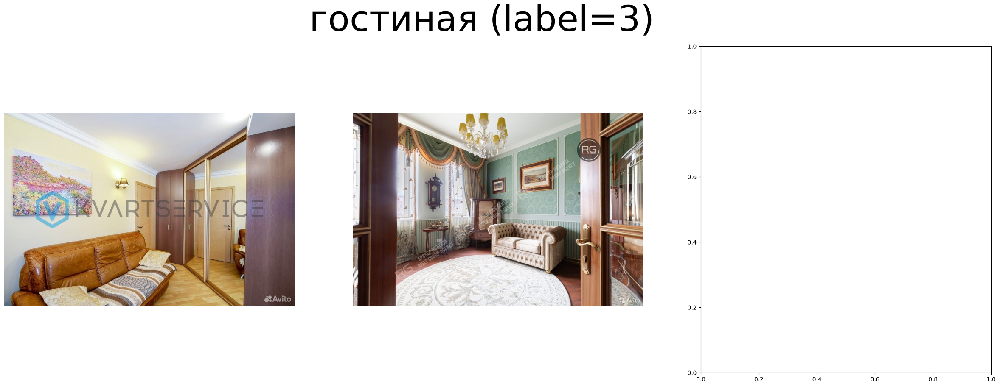

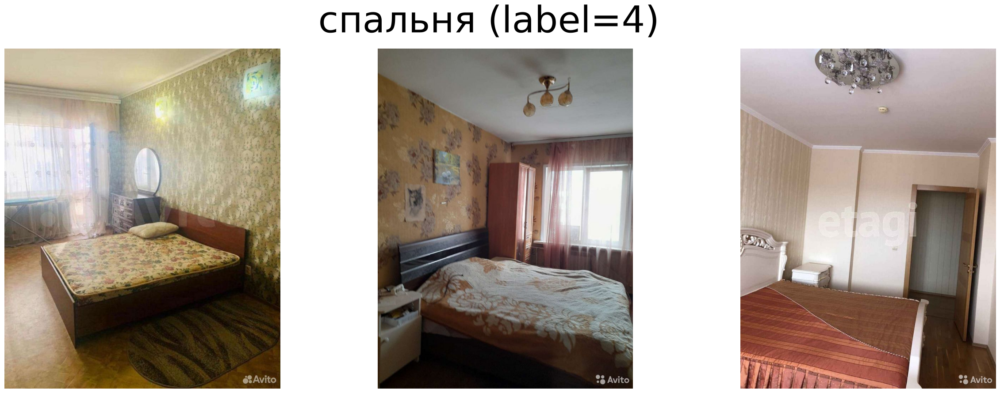

...

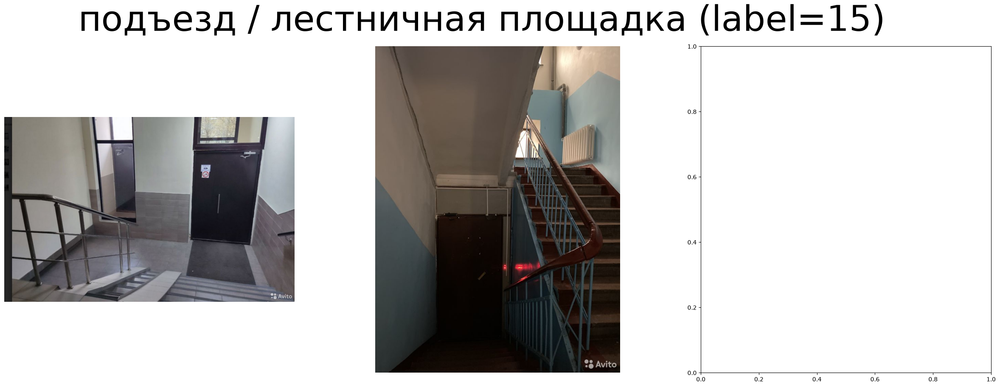

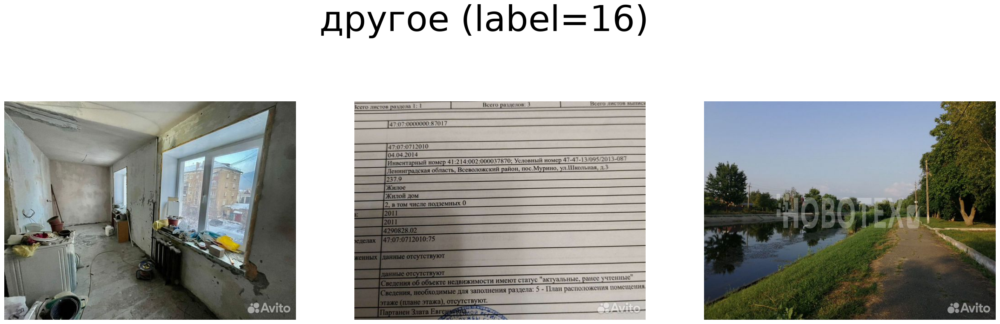

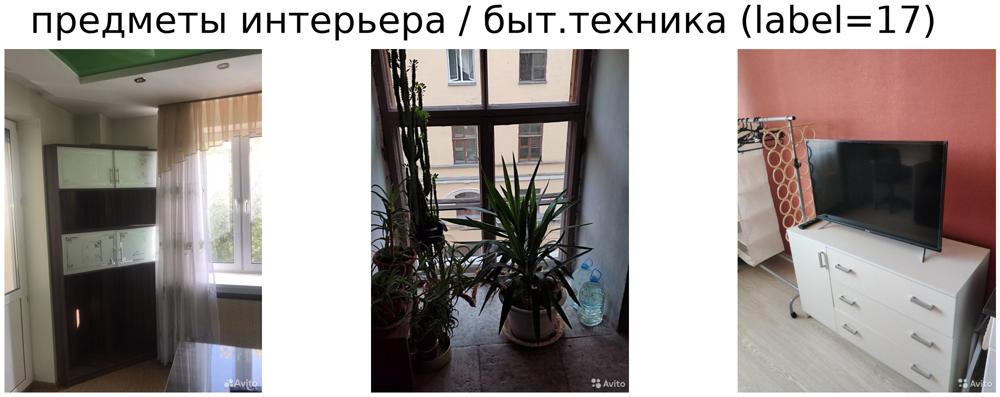

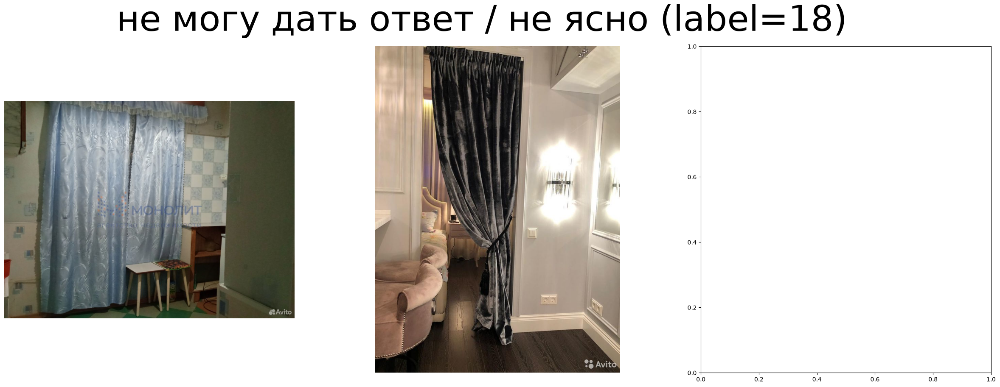

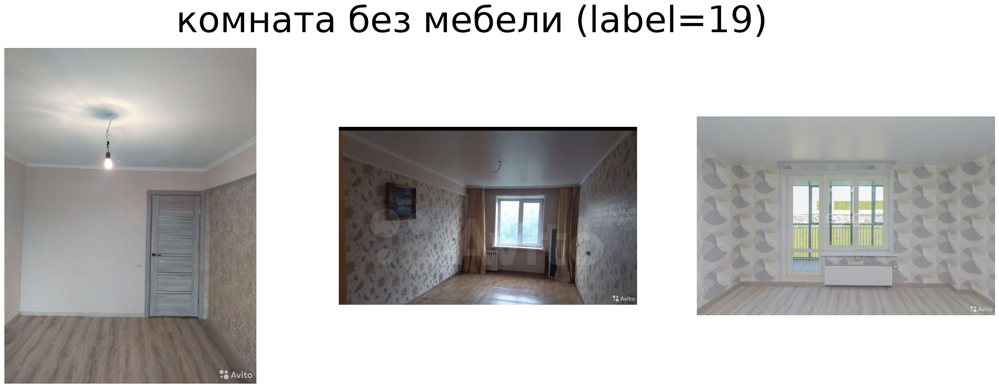

In [4]:
for i in range(20):
    print(f"Done: {i+1}/20", end="\t")
    plot_samples(df, i)

In [12]:
import pandas as pd

df = pd.read_csv("data/DATASETS_HA_dataset_course_YATASKS_1_sample_1000.csv")
df_toloka = df[["image"]].rename(columns={"image": "INPUT:image"})
df_toloka.to_csv("data/tasks.tsv", sep="\t", index=False, encoding="utf-8")

In [20]:
import pandas as pd

df = pd.read_csv("data/DATASETS_HA_YATASKS_labeled_subsample.csv")

train_indices = df.groupby('result').head(2).index

train_raw = df.loc[train_indices]
last_raw = df.drop(index=train_indices)

train_df = train_raw[['image', 'result']]
last_df = last_raw[['image', 'result']]

train_df = train_df.rename(columns={'image': 'INPUT:image', 'result': 'GOLDEN:result'})
train_df['GOLDEN:result'] = train_df['GOLDEN:result'].astype(str)

last_df = last_df.rename(columns={'image': 'INPUT:image', 'result': 'GOLDEN:result'})
last_df['GOLDEN:result'] = last_df['GOLDEN:result'].astype(str)

train_df.to_csv('data/train.tsv', sep='\t', index=False, encoding="utf-8")
last_df.to_csv('data/last.tsv', sep='\t', index=False, encoding="utf-8")

print(f"В train.tsv сохранено: {len(train_df)} строк")
print(f"В last.tsv сохранено: {len(last_df)} строк")

В train.tsv сохранено: 40 строк
В last.tsv сохранено: 42 строк
